In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
df = pd.read_csv("C:/Users/User/Downloads/Order_delivery.csv")
print(df)

        Order_ID User_ID  Restaurant_ID  Driver_ID      Item_Name  Quantity  \
0              1   U3522            358        485  Fried Chicken         3   
1              2   U9214            316         65       Sandwich         3   
2              3   U7307            357        309        Koshary         3   
3              4   U3612            420         32          Sushi         2   
4              5   U3492             73        364        Koshary         5   
...          ...     ...            ...        ...            ...       ...   
99997      99998   U2735             12         88  Fried Chicken         4   
99998      99999   U7356            570        473        Koshary         4   
99999     100000   U3960            790        283        Koshary         5   
100000    100001   U5821            345        172         Burger         2   
100001    100002   U9147            621        391          Pizza         3   

        Total_Price        Order_Time     Delivery_

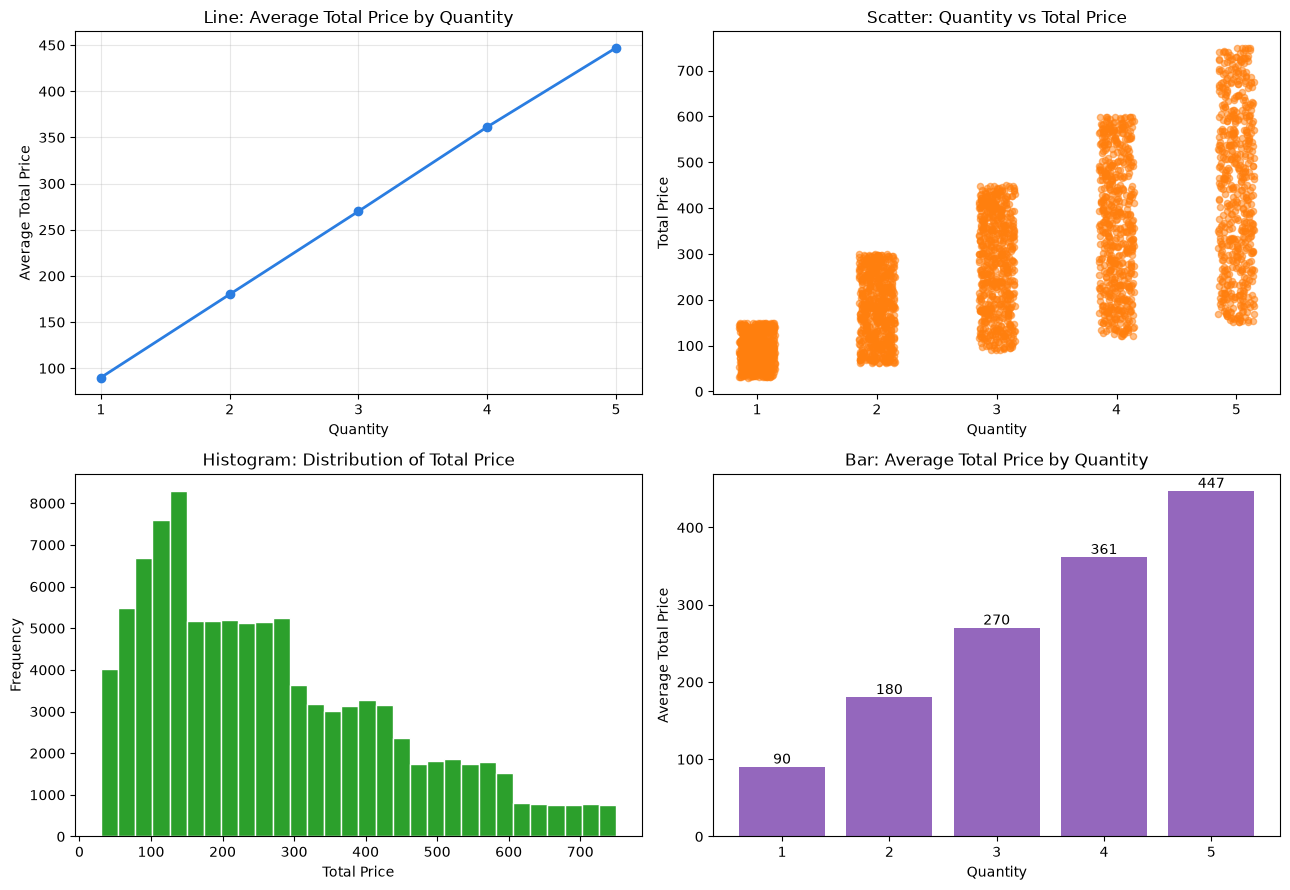

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) โหลดข้อมูล (แก้ path ให้ตรงกับที่เก็บไฟล์)
df = pd.read_csv("Order_delivery.csv")

# 2) เลือก 2 ตัวแปร
data = df[["Quantity", "Total_Price"]]

# 3) ราคาเฉลี่ยในแต่ละจำนวนชิ้น (ใช้กับ line และ bar)
avg_price = data.groupby("Quantity")["Total_Price"].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# ---------- 1) Line chart: ราคาเฉลี่ยตามจำนวนชิ้น ----------
axes[0, 0].plot(avg_price.index, avg_price.values,
                marker="o", linewidth=2, color="#2a7de1")
axes[0, 0].set_title("Line: Average Total Price by Quantity")
axes[0, 0].set_xlabel("Quantity")
axes[0, 0].set_ylabel("Average Total Price")
axes[0, 0].set_xticks(avg_price.index)
axes[0, 0].grid(True, alpha=0.3)

# ---------- 2) Scatter plot: Quantity vs Total_Price ----------
sample = data.sample(n=3000, random_state=42)  # สุ่มเพื่อไม่ให้จุดแน่นเกินไป
x_jitter = sample["Quantity"] + np.random.uniform(-0.15, 0.15, len(sample))
axes[0, 1].scatter(x_jitter, sample["Total_Price"],
                   alpha=0.5, s=20, color="#ff7f0e")
axes[0, 1].set_title("Scatter: Quantity vs Total Price")
axes[0, 1].set_xlabel("Quantity")
axes[0, 1].set_ylabel("Total Price")
axes[0, 1].set_xticks([1, 2, 3, 4, 5])

# ---------- 3) Histogram: การกระจายของ Total_Price ----------
axes[1, 0].hist(data["Total_Price"], bins=30,
                color="#2ca02c", edgecolor="white")
axes[1, 0].set_title("Histogram: Distribution of Total Price")
axes[1, 0].set_xlabel("Total Price")
axes[1, 0].set_ylabel("Frequency")

# ---------- 4) Bar chart: ราคาเฉลี่ยตามจำนวนชิ้น ----------
bars = axes[1, 1].bar(avg_price.index.astype(str), avg_price.values,
                      color="#9467bd")
axes[1, 1].bar_label(bars, fmt="%.0f")  # แสดงตัวเลขบนแท่ง
axes[1, 1].set_title("Bar: Average Total Price by Quantity")
axes[1, 1].set_xlabel("Quantity")
axes[1, 1].set_ylabel("Average Total Price")

plt.tight_layout()
plt.show()

จำนวนข้อมูล: 100,002 แถว | Correlation = 0.741
 qty  mean   p10   p90   min   max  orders   revenue  order_share  revenue_share
   1  90.0  41.7 138.1  30.0 150.0   19945 1794698.8         19.9            6.7
   2 180.1  83.7 275.9  60.0 300.0   20323 3659840.6         20.3           13.6
   3 270.0 125.1 414.3  90.0 449.9   20125 5434239.8         20.1           20.2
   4 361.4 168.7 551.5 120.0 600.0   19895 7190318.0         19.9           26.7
   5 447.1 208.7 688.4 150.0 750.0   19714 8813708.4         19.7           32.8


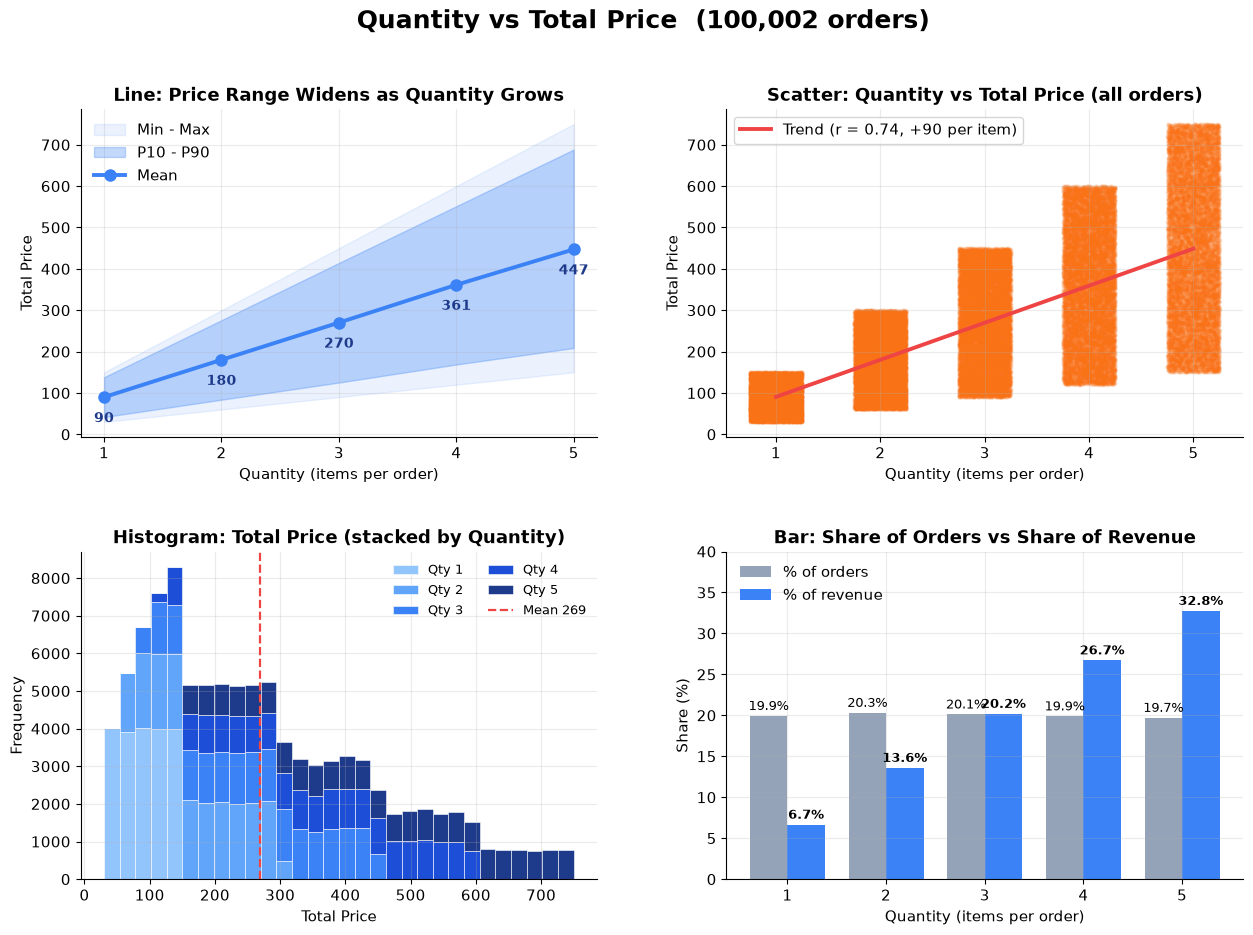

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- 1) โหลดข้อมูล + เลือก 2 ตัวแปร ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]
r = data["qty"].corr(data["price"])
print(f"จำนวนข้อมูล: {len(data):,} แถว | Correlation = {r:.3f}")

# ---------- 2) สรุปข้อมูลตามจำนวนชิ้น ----------
g = data.groupby("qty")["price"]
summary = pd.DataFrame({
    "mean": g.mean(), "p10": g.quantile(0.10), "p90": g.quantile(0.90),
    "min": g.min(), "max": g.max(), "orders": g.size(), "revenue": g.sum(),
}).reset_index()
summary["order_share"] = summary["orders"] / summary["orders"].sum() * 100
summary["revenue_share"] = summary["revenue"] / summary["revenue"].sum() * 100
print(summary.round(1).to_string(index=False))

# ---------- 3) ธีมและสี ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
BLUE, ORANGE, RED = "#3b82f6", "#f97316", "#ef4444"
QCOLORS = ["#93c5fd", "#60a5fa", "#3b82f6", "#1d4ed8", "#1e3a8a"]   # สีของ Quantity 1-5

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Quantity vs Total Price  (100,002 orders)", fontsize=18, fontweight="bold", y=0.98)
fig.subplots_adjust(hspace=0.35, wspace=0.25)

# ---------- Line: ราคาเฉลี่ย + ช่วงราคาที่พบบ่อย (P10-P90) ----------
ax = axes[0, 0]
ax.fill_between(summary["qty"], summary["min"], summary["max"], color=BLUE, alpha=0.10, label="Min - Max")
ax.fill_between(summary["qty"], summary["p10"], summary["p90"], color=BLUE, alpha=0.30, label="P10 - P90")
ax.plot(summary["qty"], summary["mean"], marker="o", markersize=8, color=BLUE, linewidth=2.8, label="Mean")
for q, m in zip(summary["qty"], summary["mean"]):
    ax.annotate(f"{m:.0f}", (q, m), textcoords="offset points", xytext=(0, -18),
                ha="center", fontsize=10, color="#1e3a8a", fontweight="bold")
ax.set_xticks(summary["qty"])
ax.set_title("Line: Price Range Widens as Quantity Grows")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Total Price")
ax.legend(loc="upper left", frameon=False)

# ---------- Scatter: ข้อมูลทั้งหมด + jitter + เส้นแนวโน้ม ----------
ax = axes[0, 1]
rng = np.random.default_rng(42)
x_jit = data["qty"] + rng.uniform(-0.25, 0.25, len(data))
ax.scatter(x_jit, data["price"], s=4, alpha=0.08, color=ORANGE, rasterized=True)
slope, intercept = np.polyfit(data["qty"], data["price"], 1)
ax.plot([1, 5], [slope + intercept, 5 * slope + intercept], color=RED, linewidth=2.8,
        label=f"Trend (r = {r:.2f}, +{slope:.0f} per item)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_title("Scatter: Quantity vs Total Price (all orders)")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Total Price")
ax.legend(loc="upper left", frameon=True)

# ---------- Histogram: Total_Price แยกสีตาม Quantity (stacked) ----------
ax = axes[1, 0]
groups = [data.loc[data["qty"] == q, "price"] for q in range(1, 6)]
ax.hist(groups, bins=30, stacked=True, color=QCOLORS, edgecolor="white", linewidth=0.4,
        label=[f"Qty {q}" for q in range(1, 6)])
ax.axvline(data["price"].mean(), color=RED, linestyle="--", linewidth=1.6,
           label=f"Mean {data['price'].mean():.0f}")
ax.set_title("Histogram: Total Price (stacked by Quantity)")
ax.set_xlabel("Total Price")
ax.set_ylabel("Frequency")
ax.legend(frameon=False, ncol=2, fontsize=9)

# ---------- Bar: สัดส่วนจำนวนออเดอร์ vs สัดส่วนรายได้ ----------
ax = axes[1, 1]
x = np.arange(5)
w = 0.38
b1 = ax.bar(x - w / 2, summary["order_share"], w, color="#94a3b8", label="% of orders")
b2 = ax.bar(x + w / 2, summary["revenue_share"], w, color=BLUE, label="% of revenue")
ax.bar_label(b1, fmt="%.1f%%", fontsize=9, padding=2)
ax.bar_label(b2, fmt="%.1f%%", fontsize=9, padding=2, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(summary["qty"])
ax.set_ylim(0, 40)
ax.set_title("Bar: Share of Orders vs Share of Revenue")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Share (%)")
ax.legend(frameon=False, loc="upper left")

plt.show()

Linear Regression : R2 train = 0.5486 | R2 test = 0.5490
  สมการ: Quantity = 0.00613 * Total_Price + 1.3429

 degree  R2_train  R2_test     gap
      1    0.5486   0.5490 -0.0005
      2    0.5912   0.5909  0.0003
      3    0.5431   0.5427  0.0004
      4    0.4750   0.4749  0.0001


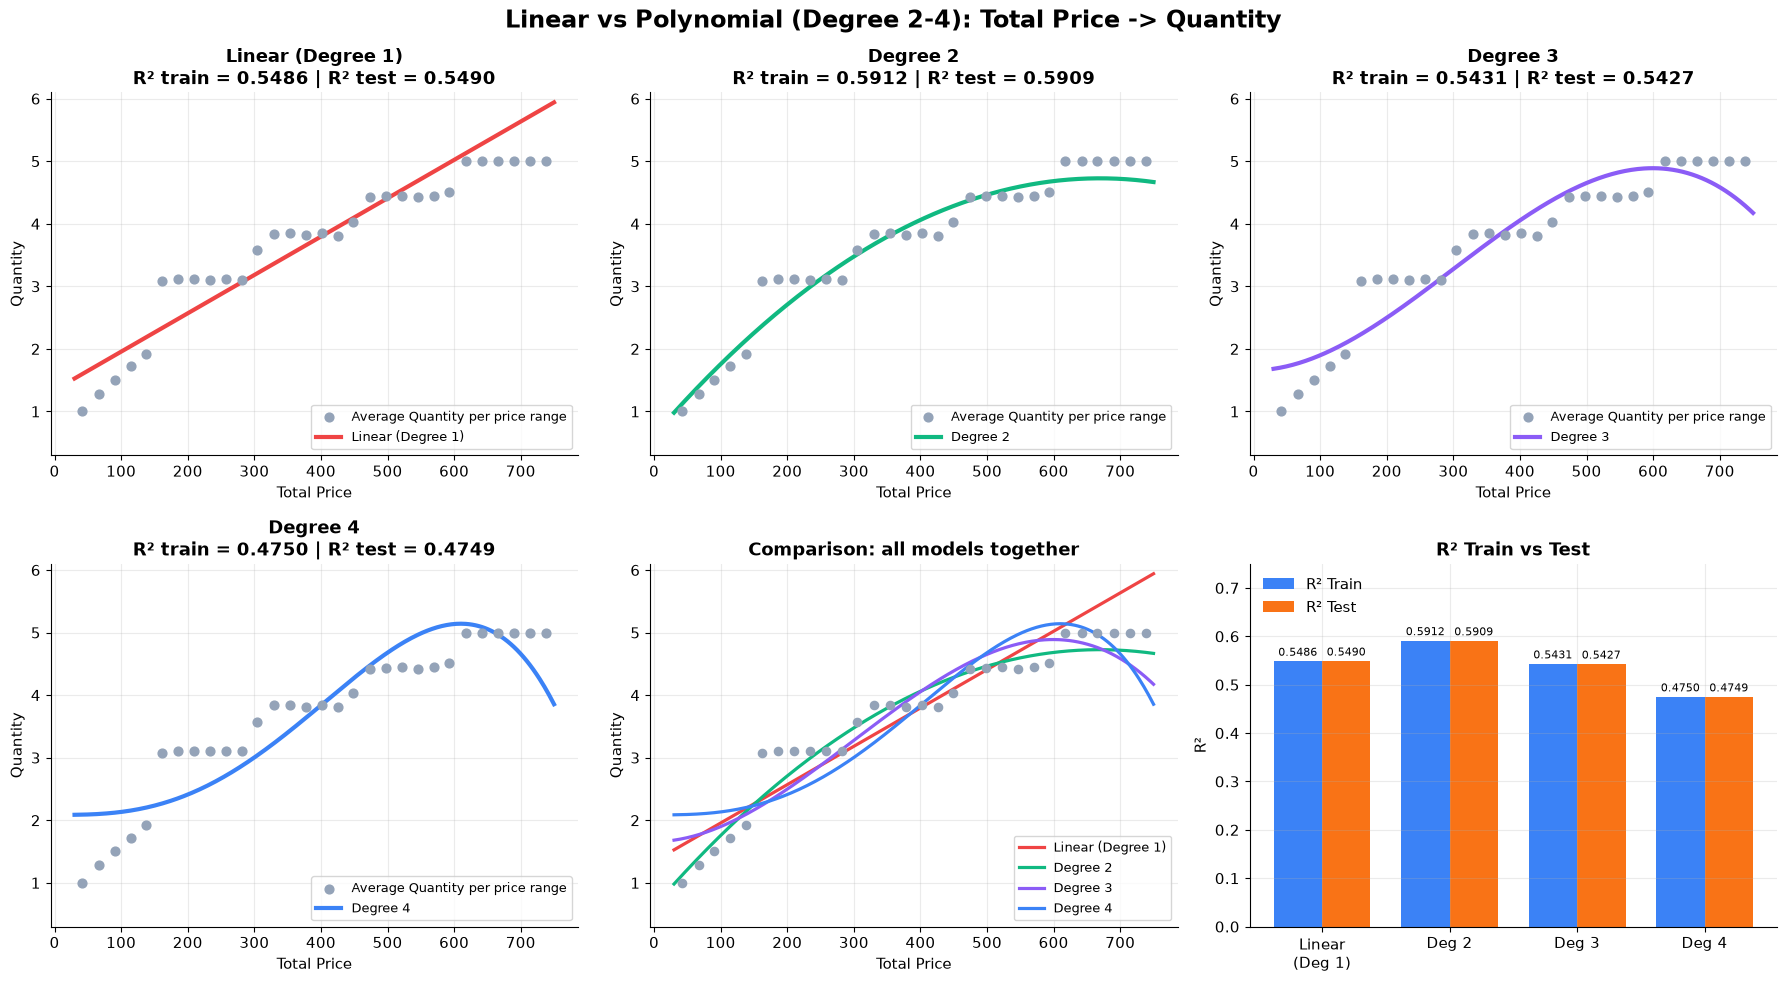

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- 1) โหลดข้อมูล + เลือกตัวแปร ----------
df = pd.read_csv(CSV_PATH)
X = df[["Total_Price"]]   # ตัวแปรต้น  (ราคารวมของออเดอร์)
y = df["Quantity"]        # ตัวแปรตาม (จำนวนชิ้น)

# ---------- 2) แบ่ง train / test (80 / 20) ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------- 3) Linear Regression (เส้นตรง) ----------
linear = LinearRegression().fit(X_train, y_train)
lin_train = r2_score(y_train, linear.predict(X_train))
lin_test = r2_score(y_test, linear.predict(X_test))
print(f"Linear Regression : R2 train = {lin_train:.4f} | R2 test = {lin_test:.4f}")
print(f"  สมการ: Quantity = {linear.coef_[0]:.5f} * Total_Price + {linear.intercept_:.4f}\n")

# ---------- 4) Polynomial degree 1, 2, 3, 4 ----------
degrees = [1, 2, 3, 4]
rows, models = [], {}
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    rows.append({
        "degree": d,
        "R2_train": r2_score(y_train, model.predict(X_train)),
        "R2_test": r2_score(y_test, model.predict(X_test)),
    })
    models[d] = model

res = pd.DataFrame(rows)
res["gap"] = res["R2_train"] - res["R2_test"]
print(res.round(4).to_string(index=False))

# ---------- 5) วาดกราฟ ----------
bins = pd.cut(df["Total_Price"], bins=30)
binned = df.groupby(bins, observed=True).agg(price=("Total_Price", "mean"),
                                              qty=("Quantity", "mean"))
xs = pd.DataFrame({"Total_Price": np.linspace(30, 750, 300)})
colors = {1: "#ef4444", 2: "#10b981", 3: "#8b5cf6", 4: "#3b82f6"}
names = {1: "Linear (Degree 1)", 2: "Degree 2", 3: "Degree 3", 4: "Degree 4"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Linear vs Polynomial (Degree 2-4): Total Price -> Quantity",
             fontsize=17, fontweight="bold")

# 5.1 กราฟแยก: 1 กราฟ = 1 เส้น (Linear, Degree 2, 3, 4)
for ax, d in zip([axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0]], degrees):
    r = res.loc[d - 1]
    ax.scatter(binned["price"], binned["qty"], s=40, color="#94a3b8", zorder=3,
               label="Average Quantity per price range")
    ax.plot(xs["Total_Price"], models[d].predict(xs), linewidth=3, color=colors[d], label=names[d])
    ax.set_title(f"{names[d]}\nR² train = {r['R2_train']:.4f} | R² test = {r['R2_test']:.4f}")
    ax.set_xlabel("Total Price")
    ax.set_ylabel("Quantity")
    ax.set_ylim(0.3, 6.1)
    ax.legend(loc="lower right", frameon=True, fontsize=9)

# 5.2 กราฟเทียบทุกเส้นรวมกัน
ax = axes[1, 1]
ax.scatter(binned["price"], binned["qty"], s=35, color="#94a3b8", zorder=3)
for d in degrees:
    ax.plot(xs["Total_Price"], models[d].predict(xs), linewidth=2.3, color=colors[d], label=names[d])
ax.set_title("Comparison: all models together")
ax.set_xlabel("Total Price")
ax.set_ylabel("Quantity")
ax.set_ylim(0.3, 6.1)
ax.legend(loc="lower right", frameon=True, fontsize=9)

# 5.3 กราฟเทียบ R² train vs test
ax = axes[1, 2]
x = np.arange(len(degrees)); w = 0.38
b1 = ax.bar(x - w / 2, res["R2_train"], w, color="#3b82f6", label="R² Train")
b2 = ax.bar(x + w / 2, res["R2_test"], w, color="#f97316", label="R² Test")
ax.bar_label(b1, fmt="%.4f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.4f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(["Linear\n(Deg 1)", "Deg 2", "Deg 3", "Deg 4"])
ax.set_ylim(0, 0.75)
ax.set_title("R² Train vs Test")
ax.set_ylabel("R²")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()